[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MusicalInformatics/miws26/blob/main/introduction/intro_to_fourier_analysis.ipynb)

In [ ]:
try:
    import google.colab
    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    # Install python packages
    ! pip install git+https://github.com/CPJKU/partitura.git@develop ipympl

    # To be able to access helper modules and data in the repo for this tutorial
    # (not necessary if the jupyter notebook is run locally instead of google colab)
    !git clone --recurse-submodules https://github.com/MusicalInformatics/miws26.git
    import sys
    sys.path.insert(0, "./miws26/introduction/")

    # Needed for interactive matplotlib figures (%matplotlib widget) on Colab
    from google.colab import output
    output.enable_custom_widget_manager()

# Introduction to Fourier Analysis

This notebook presents a very short (and not very formal!) introduction to Fourier analysis.

Music signals can be fairly complex. Because of this, we would like to be able to extract relevant information. This is especially true for audio. One of the most useful representations, is representing information in terms of sinusoids.

But before going there, let's start with a basic mathematical question: how do we compute the similarity between two functions? (In here, imagine that we want to represent audio signals in terms of mathematical functions over time).

Imagine that we have real valued functions $f:\mathbb{R} \mapsto \mathbb{R}$ and $g:\mathbb{R} \mapsto \mathbb{R}$.


In [9]:
# Add here 

# Fourier Analysis of a Piano Tone

In this notebook we look at the harmonic content of a piano tone using the Fourier transform.

In the interactive plot below:

- **Left click** on the spectrum adds a vertical line (a harmonic) at that frequency.
- **Right click** removes the most recently added line.

The audio player below the figure is updated every time the lines change, so you can listen to the additive synthesis of the harmonics you selected.

/Users/carlos/Documents/JKU/Teaching/MusicalInformatics2026WS/miws26/introduction/utils.py:125: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, signal = wavfile.read(filename)


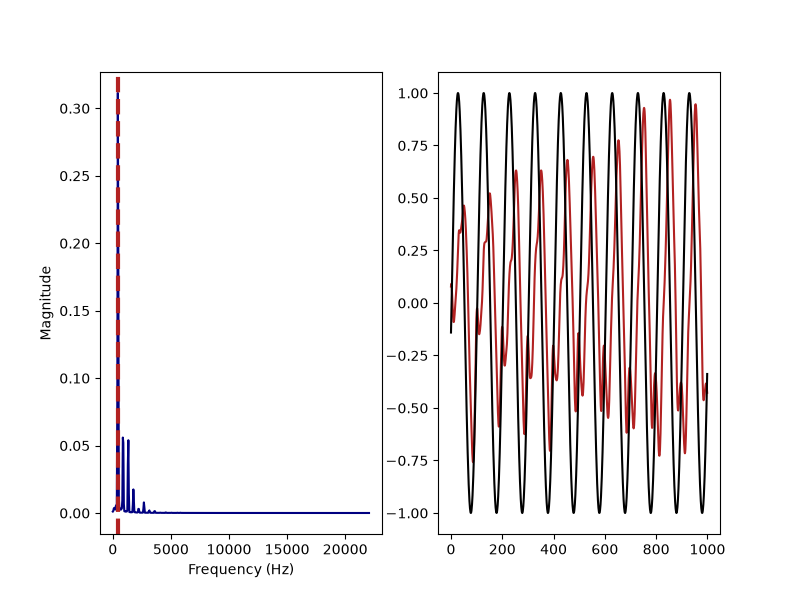

Audio(value=b'RIFF\xacX\x01\x00WAVEfmt \x10\x00\x00\x00\x01\x00\x01\x00D\xac\x00\x00\x88X\x01\x00\x02\x00\x10\…

In [1]:
%matplotlib widget
import os

import matplotlib.pyplot as plt
from utils import InteractiveToneAnalyzer, load_audio, ipd, PATH

signal, sr = load_audio(os.path.join(PATH, "example_data", "a4_piano.wav"))

display(ipd.Audio(
            data=signal,
            rate=sr,
            normalize=True,
            element_id="original_signal",
        ))

plot = InteractiveToneAnalyzer(signal=signal, sample_rate=sr)

plot.show()

In [ ]:
plot.harmonics_dist(440)




In [ ]:
fig, ax = plt.subplots(1)

ax.plot(plot.synth_signal[1000:2000] / abs(plot.synth_signal).max())
ax.plot(signal[1000:2000] / abs(signal).max())
plt.show()

In [ ]:
type(plot.ax)

In [ ]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display, Audio
from typing import Tuple


def generate_audio_signals(delta_f: float=0) -> Tuple[np.ndarray, np.ndarray]:
    fs = 44100 
    t = np.linspace(0, 1, fs)

    f1 = 440
    f2 = (1 + delta_f) * f1

    # Generate two different tones
    signal1 = 0.5 * np.sin(2 * np.pi * f1 * t)  # A 440 Hz tone
    signal2 = 0.5 * np.sin(2 * np.pi * f2 * t)  # A 550 Hz tone

    return signal1, signal2

# Function to display the audio players and the text input field for user response
def show_comparison(index: int, delta_f: float = 0) -> None:
    # Generate the signals
    signal1, signal2 = generate_audio_signals(delta_f)

    # Create Output widgets to hold the Audio objects
    out1 = widgets.Output()
    out2 = widgets.Output()

    with out1:
        display(Audio(data=signal1, rate=44100, autoplay=False))
    with out2:
        display(Audio(data=signal2, rate=44100, autoplay=False))

    # Display the two outputs side by side
    hbox = widgets.HBox([out1, out2])

    # Create input field for user to enter a response (a number)
    response = widgets.IntText(description="Your Answer:")

    # Create a button for submitting the answer
    button = widgets.Button(description="Submit")

    # Define a function to handle button click
    def on_button_click(b):
        # Store the response value when the button is clicked
        answers[index] = response.value
        print(f"Answer recorded: {response.value}")
        response.value = 0  # Clear input field for next comparison

    button.on_click(on_button_click)

    # Display everything
    display(hbox, response, button)

delta_semitone = 2 ** (1/12) - 1

delta_fs = np.linspace(-delta_semitone, delta_semitone, 10)
delta_fs = np.random.normal(loc=0, scale=0.5*delta_semitone, size=10)
delta_fs.sort()
# Create an array to store user answers
answers = np.zeros(len(delta_fs))
sort_idxs = np.arange(len(delta_fs))
np.random.shuffle(sort_idxs)
# Display N comparisons (you can adjust N)
N = 5
for i, si in enumerate(sort_idxs):
    print(f"Comparison {i+1}")
    show_comparison(index=si, delta_f=delta_fs[si])


In [ ]:
delta_fs

In [ ]:
answers